# Airline Loyalty Program: Churn Prediction & Customer Segmentation

**Business problem:** The marketing team wants to (1) spot members likely to leave, (2) understand which members are most valuable, and (3) know what to do about it.

**Data:** about 16,700 loyalty members of a Canadian airline. `Customer Loyalty History.csv` has one row per member; `Customer Flight Activity.csv` has one row per member per month for 2017-2018.

**What this notebook delivers**

| Deliverable | Method |
|---|---|
| Churn risk score for every active member | Logistic Regression and Random Forest (compared with a simple baseline) |
| Customer segments | K-Means (k = 4) |
| Retention actions per segment | Based on segment profiles and risk tiers |

### The key design decision: look at 2017, predict 2018

A churn model must predict the **future** from the **past**. So the data is split by time, not just by rows:

```
 Jan 2017 ---------------- Dec 2017 | Jan 2018 ---------------- Dec 2018
   FEATURES come from here          |      CHURN LABEL comes from here
   (flights, points, tenure ...)    |      (did the member cancel in 2018?)
```

If features and label come from the same months, the model is partly "predicting" something its own inputs already reveal (for example, a member who cancelled in 2017 naturally has no flights afterwards). That produces suspiciously perfect scores that would not hold up in real use. Splitting by time avoids this, and every number in this notebook is a genuine prediction.

## 1. Load the data

In [18]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

def find_file(*names):
    """Look for the CSV next to the notebook (or in a data/ folder)."""
    for folder in [Path("."), Path("data"), Path("/mnt/user-data/uploads")]:
        for name in names:
            if (folder / name).exists():
                return folder / name
    raise FileNotFoundError(f"Put one of these files next to the notebook: {names}")

loyalty = pd.read_csv(find_file("Customer Loyalty History.csv", "Customer Loyalty History (1).csv",
                                "Customer_Loyalty_History.csv", "Customer_Loyalty_History__1_.csv"))
flights = pd.read_csv(find_file("Customer Flight Activity.csv", "Customer Flight Activity (1).csv",
                                "Customer_Flight_Activity.csv", "Customer_Flight_Activity__1_.csv"))

print(f"Loyalty history : {loyalty.shape[0]:,} rows x {loyalty.shape[1]} columns (one row per member)")
print(f"Flight activity : {flights.shape[0]:,} rows x {flights.shape[1]} columns (one row per member per month)")

Loyalty history : 16,737 rows x 16 columns (one row per member)
Flight activity : 392,936 rows x 8 columns (one row per member per month)


## 2. Understand the data
Before building anything, check what is in the files and what is wrong with them.

In [19]:
display(loyalty.head(3))
display(flights.head(3))

print("Missing values in loyalty file:")
print(loyalty.isna().sum()[lambda s: s > 0])
print("\nDuplicate rows in flight file:", flights.duplicated().sum())
print("Years covered by flight file :", sorted(flights["Year"].unique()))

,Loyalty Number,Country,Province,City,Postal Code,Gender,Education,Salary,Marital Status,Loyalty Card,CLV,Enrollment Type,Enrollment Year,Enrollment Month,Cancellation Year,Cancellation Month
0,480934,Canada,Ontario,Toronto,M2Z 4K1,Female,Bachelor,83236.0,Married,Star,3839.14,Standard,2016,2,NaN,NaN
1,549612,Canada,Alberta,Edmonton,T3G 6Y6,Male,College,NaN,Divorced,Star,3839.61,Standard,2016,3,NaN,NaN
2,429460,Canada,British Columbia,Vancouver,V6E 3D9,Male,College,NaN,Single,Star,3839.75,Standard,2014,7,2018.0,1.0


,Loyalty Number,Year,Month,Total Flights,Distance,Points Accumulated,Points Redeemed,Dollar Cost Points Redeemed
0,100590,2018,6,12,15276,22914.0,0,0
1,100590,2018,7,12,9168,13752.0,0,0
2,100590,2018,5,4,6504,9756.0,0,0


Missing values in loyalty file:
Salary                 4238
Cancellation Year     14670
Cancellation Month    14670
dtype: int64

Duplicate rows in flight file: 1922
Years covered by flight file : [np.int64(2017), np.int64(2018)]


In [20]:
# 1) How many members ever cancelled, and when?
cancelled = loyalty["Cancellation Year"].notna().sum()
print(f"Members who ever cancelled: {cancelled:,} ({cancelled / len(loyalty):.1%})")
print("\nCancellations by year:")
print(loyalty["Cancellation Year"].value_counts().sort_index().astype(int).to_string())

# 2) Salary problems
print("\nNegative salaries:", (loyalty["Salary"] < 0).sum())
print("Missing salary by education level:")
print(loyalty.loc[loyalty["Salary"].isna(), "Education"].value_counts().to_string())

# 3) Can the two files be joined safely?
in_both = set(loyalty["Loyalty Number"]) & set(flights["Loyalty Number"])
print(f"\nMembers in both files: {len(in_both):,} of {loyalty['Loyalty Number'].nunique():,}")

# 4) Is a single zero-flight month unusual?
print(f"Share of member-months with zero flights: {(flights['Total Flights'] == 0).mean():.1%}")

# 5) Are 'Points Accumulated' and 'Distance' the same thing?
same = (flights["Points Accumulated"] == flights["Distance"]).mean()
print(f"Rows where Points Accumulated == Distance: {same:.1%}")

# 6) Data quirk: flights recorded BEFORE the member enrolled
chk = flights.merge(loyalty[["Loyalty Number", "Enrollment Year", "Enrollment Month"]], on="Loyalty Number")
before = (chk["Year"] * 12 + chk["Month"]) < (chk["Enrollment Year"] * 12 + chk["Enrollment Month"])
print(f"Flight rows dated before enrolment with flights > 0: {(before & (chk['Total Flights'] > 0)).sum():,}")

Members who ever cancelled: 2,067 (12.3%)

Cancellations by year:
Cancellation Year
2013.0     43
2014.0    181
2015.0    265
2016.0    427
2017.0    506
2018.0    645

Negative salaries: 20
Missing salary by education level:
Education
College    4238

Members in both files: 16,737 of 16,737
Share of member-months with zero flights: 54.5%
Rows where Points Accumulated == Distance: 98.6%
Flight rows dated before enrolment with flights > 0: 3,222


**What the checks show**

- **Churn is a real but modest event:** 2,067 members (12.3%) ever cancelled, spread over 2013-2018. Flight data only exists for 2017-2018.
- **One quiet month means nothing:** 54.5% of member-months have zero flights, so a single month of inactivity cannot be a churn signal.
- **Join is clean:** every member appears in both files.
- **Fixes needed:** 1,922 duplicate flight rows, 20 negative salaries (sign typos), and 4,238 missing salaries that all belong to College students (students have no salary, so 0 is correct).
- **Redundant column:** `Points Accumulated` equals `Distance` in 98.6% of rows, so it carries no extra information and is not used.
- **A quirk we leave alone:** 3,222 flight rows are dated before the member's enrolment date. We cannot tell whether the date or the flight is wrong, so we make no adjustment and note it as a limitation.

## 3. Clean the data
Only the fixes that the checks above justify.

In [21]:
# Remove exact duplicate flight rows
flights = flights.drop_duplicates().copy()

# Negative salaries: sign typos, so take the absolute value
loyalty["Salary"] = loyalty["Salary"].abs()

# Missing salary: confirm it only happens for College students, then use 0 (no income)
assert loyalty.loc[loyalty["Salary"].isna(), "Education"].eq("College").all()
loyalty["Salary"] = loyalty["Salary"].fillna(0)

print("Flight rows after removing duplicates:", f"{len(flights):,}")
print("Missing salaries left:", loyalty["Salary"].isna().sum())

Flight rows after removing duplicates: 391,014
Missing salaries left: 0


## 4. Who are we predicting for, and what counts as churn?

**Who we score:** members who were active on 1 January 2018, meaning they enrolled by December 2017 and had not already cancelled.

**What counts as churn:** the member **cancelled their membership during 2018**.

Why a formal cancellation and not "stopped flying"? It is an unambiguous, recorded event. A "zero flights" definition would mostly flag members who were never active in the first place, which is easy to predict but not useful to marketing.

In [22]:
total = len(loyalty)

joined_in_2018 = loyalty["Enrollment Year"] >= 2018
left_before_2018 = loyalty["Cancellation Year"] < 2018          # NaN (never cancelled) -> False

members = loyalty[~joined_in_2018 & ~left_before_2018].copy()
members["churned"] = (members["Cancellation Year"] == 2018).astype(int)

print(f"All members in file                         : {total:,}")
print(f"  - joined in 2018 (not members in 2017)    : {joined_in_2018.sum():,}")
print(f"  - already cancelled before 2018           : {(~joined_in_2018 & left_before_2018).sum():,}")
print(f"Members we can score (active on 1 Jan 2018) : {len(members):,}")
print(f"\nChurned in 2018 (cancelled membership)      : {members['churned'].sum():,}  ({members['churned'].mean():.2%})")

All members in file                         : 16,737
  - joined in 2018 (not members in 2017)    : 3,010
  - already cancelled before 2018           : 1,422
Members we can score (active on 1 Jan 2018) : 12,305

Churned in 2018 (cancelled membership)      : 486  (3.95%)


**Result:** 12,305 members can be scored and 486 of them (3.95%) churned in 2018.

With only about 4 in 100 members churning, **accuracy is a useless metric** (saying "nobody churns" would be 96% accurate). Instead the model is judged on:

- **ROC-AUC:** how well it ranks churners above non-churners (0.5 = random, 1.0 = perfect)
- **PR-AUC:** precision/recall quality when positives are rare (random = 0.04 here)
- **Churners caught in the top 20%:** if marketing can only contact 1 in 5 members, how many churners are in that group? Random contact would catch 20%.

## 5. Build features from 2017 only

All features use **only 2017 data** and describe a member as of December 2017:

| Feature | Meaning |
|---|---|
| `Tenure_Months` | Months since the member enrolled |
| `Flights_2017` | Total flights in 2017 |
| `Active_Months` | Number of months in 2017 with at least one flight |
| `Flights_Last_3M` | Flights in Oct-Dec 2017 (recent engagement) |
| `Months_Since_Last_Flight` | Months of silence at the end of 2017 (12 if no flights all year) |
| `Points_Redeemed` | Points used in 2017 |
| `CLV_log` | Customer lifetime value (log-transformed because it is right-skewed) |
| `Salary`, `Loyalty_Card`, `Education_Level` | Profile information (card and education as ordered numbers) |

Gender, marital status and province are left out because the exploration below shows churn is almost the same across them.

In [23]:
# ONLY 2017 flight data is used to build features
f17 = flights[flights["Year"] == 2017].copy()
assert f17["Year"].max() == 2017          # safety check: no 2018 information leaks in

g = f17.groupby("Loyalty Number")
feat = pd.DataFrame({
    "Flights_2017":     g["Total Flights"].sum(),
    "Active_Months":    g["Total Flights"].apply(lambda s: (s > 0).sum()),     # months with at least 1 flight
    "Points_Redeemed":  g["Points Redeemed"].sum(),
    "Flights_Last_3M":  f17[f17["Month"] >= 10].groupby("Loyalty Number")["Total Flights"].sum(),
})
last_flight_month = f17[f17["Total Flights"] > 0].groupby("Loyalty Number")["Month"].max()
feat["Months_Since_Last_Flight"] = 12 - last_flight_month        # measured at end of Dec 2017
feat = feat.reset_index()

data = members.merge(feat, on="Loyalty Number", how="left")

# Members with no 2017 flights at all: zero activity, and "12 months" since last flight
for col in ["Flights_2017", "Active_Months", "Points_Redeemed", "Flights_Last_3M"]:
    data[col] = data[col].fillna(0)
data["Months_Since_Last_Flight"] = data["Months_Since_Last_Flight"].fillna(12)

# Profile features (known at the end of 2017)
data["Tenure_Months"] = (2017 - data["Enrollment Year"]) * 12 + (12 - data["Enrollment Month"])
data["CLV_log"] = np.log1p(data["CLV"])                       # CLV is right-skewed
data["Loyalty_Card"] = data["Loyalty Card"].map({"Star": 0, "Nova": 1, "Aurora": 2})
data["Education_Level"] = data["Education"].map(
    {"High School or Below": 0, "College": 1, "Bachelor": 2, "Master": 3, "Doctor": 4})

feature_cols = ["Tenure_Months", "Flights_2017", "Active_Months", "Flights_Last_3M",
                "Months_Since_Last_Flight", "Points_Redeemed", "CLV_log", "Salary",
                "Loyalty_Card", "Education_Level"]

print("Rows:", len(data), "| Features:", len(feature_cols), "| Missing values:", data[feature_cols].isna().sum().sum())
data[feature_cols + ["churned"]].describe().T.round(2)

Rows: 12305 | Features: 10 | Missing values: 0


,count,mean,std,min,25%,50%,75%,max
Tenure_Months,12305.0,33.47,20.34,0.00,16.00,33.00,51.0,68.00
Flights_2017,12305.0,17.35,7.97,0.00,13.00,18.00,23.0,61.00
Active_Months,12305.0,6.35,2.65,0.00,5.00,7.00,8.0,20.00
Flights_Last_3M,12305.0,4.27,2.82,0.00,2.00,4.00,6.0,20.00
Months_Since_Last_Flight,12305.0,1.20,2.65,0.00,0.00,0.00,1.0,12.00
Points_Redeemed,12305.0,435.83,492.08,0.00,0.00,394.00,682.0,3427.00
CLV_log,12305.0,8.75,0.65,7.55,8.29,8.66,9.1,11.21
Salary,12305.0,59538.88,45365.26,0.00,0.00,64094.00,83349.0,299953.00
Loyalty_Card,12305.0,0.75,0.77,0.00,0.00,1.00,1.0,2.00
Education_Level,12305.0,1.77,0.78,0.00,1.00,2.00,2.0,4.00


## 6. Explore: what does churn look like?

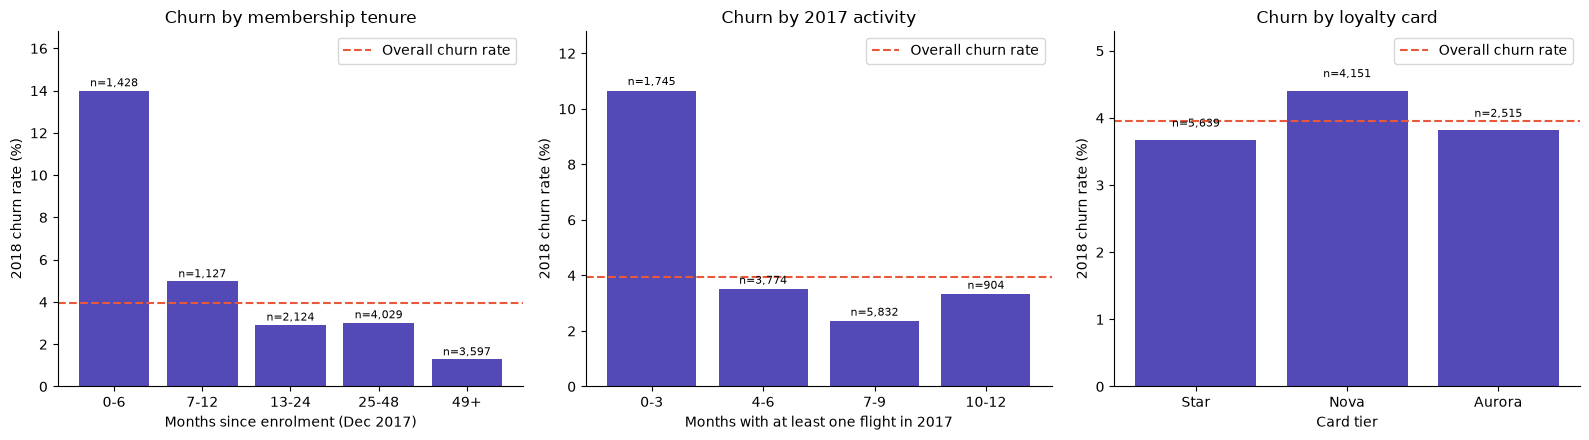

Churn rate (%) for other groups - nearly flat, so demographics are left out of the model:

Gender
Gender
Female    3.79
Male      4.11

Marital Status
Marital Status
Divorced    3.84
Married     3.98
Single      3.94

Education
Education
Bachelor                3.92
College                 4.08
Doctor                  3.97
High School or Below    2.95
Master                  4.95


In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

def churn_bar(ax, groups, title, xlabel):
    s = data.groupby(groups, observed=True)["churned"].agg(["mean", "size"])
    bars = ax.bar(s.index.astype(str), s["mean"] * 100, color="#534AB7")
    ax.axhline(data["churned"].mean() * 100, color="#E8593C", ls="--", label="Overall churn rate")
    for b, n in zip(bars, s["size"]):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.2, f"n={n:,}", ha="center", fontsize=8)
    ax.set_ylim(0, s["mean"].max() * 100 * 1.2)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel("2018 churn rate (%)"); ax.legend(loc="upper right")
    return s

tenure_bucket = pd.cut(data["Tenure_Months"], [-1, 6, 12, 24, 48, 100],
                       labels=["0-6", "7-12", "13-24", "25-48", "49+"])
active_bucket = pd.cut(data["Active_Months"], [-1, 3, 6, 9, 12], labels=["0-3", "4-6", "7-9", "10-12"])

s1 = churn_bar(axes[0], tenure_bucket, "Churn by membership tenure", "Months since enrolment (Dec 2017)")
s2 = churn_bar(axes[1], active_bucket, "Churn by 2017 activity", "Months with at least one flight in 2017")
card = pd.Categorical(data["Loyalty Card"], categories=["Star", "Nova", "Aurora"], ordered=True)
s3 = churn_bar(axes[2], card, "Churn by loyalty card", "Card tier")
plt.tight_layout(); plt.show()

print("Churn rate (%) for other groups - nearly flat, so demographics are left out of the model:")
for col in ["Gender", "Marital Status", "Education"]:
    print(f"\n{col}"); print((data.groupby(col)["churned"].mean() * 100).round(2).to_string())

**What stands out**

- **Tenure is the strongest pattern:** members in their first 6 months churned at **14.0%**, versus about 3% for members with 13-48 months and **1.3%** for members with 49+ months.
- **Low activity matters too:** members who flew in 3 or fewer months of 2017 churned at **10.7%**, versus roughly 2-3.5% for members active in 4-12 months. (Part of this overlaps with tenure, because new members have had less time to fly.)
- **Loyalty card tier barely matters:** Star 3.7%, Nova 4.4%, Aurora 3.8%. A member's tier does not tell you whether they are at risk.
- **Demographics are flat:** gender, marital status and education all sit close to the 3.9% average.

The sample size is printed above each bar. Small groups can look dramatic by chance, so always read a rate together with its `n`.

## 7. Churn prediction model

Three models are compared so the result is not taken on faith:

1. **Baseline: tenure only.** A one-feature model. Any more complex model has to beat this to justify its complexity.
2. **Logistic Regression.** Simple, explainable baseline for all 10 features.
3. **Random Forest.** Many decision trees voting together; can capture non-linear patterns.

Both full models use `class_weight="balanced"` so the rare churners are not ignored. Members are split 80/20 with `stratify` (same churn rate in both parts). 5-fold cross-validation on the training part gives a second, more stable estimate of AUC.

In [25]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, ConfusionMatrixDisplay, precision_score, recall_score

X = data[feature_cols]
y = data["churned"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print(f"Train: {len(X_train):,} members ({y_train.sum()} churners) | Test: {len(X_test):,} members ({y_test.sum()} churners)")
print(f"Churn rate  train: {y_train.mean():.2%} | test: {y_test.mean():.2%}")

Train: 9,844 members (389 churners) | Test: 2,461 members (97 churners)
Churn rate  train: 3.95% | test: 3.94%


In [26]:
# Three models: a one-feature baseline, a simple model, and a tree-based model
models = {
    "Baseline: tenure only": (make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced")),
                              ["Tenure_Months"]),
    "Logistic Regression":   (make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000)),
                              feature_cols),
    "Random Forest":         (RandomForestClassifier(n_estimators=300, max_depth=4, min_samples_leaf=40,
                                                     class_weight="balanced", random_state=42, n_jobs=-1),
                              feature_cols),
}

rows, test_scores = [], {}
for name, (model, cols) in models.items():
    cv_auc = cross_val_score(model, X_train[cols], y_train, cv=cv, scoring="roc_auc")
    model.fit(X_train[cols], y_train)
    p = model.predict_proba(X_test[cols])[:, 1]
    test_scores[name] = p

    top_20 = np.argsort(-p)[: int(0.20 * len(p))]                    # the 20% highest-risk members
    caught = y_test.values[top_20].sum() / y_test.sum()
    rows.append({"Model": name,
                 "CV ROC-AUC (train)": f"{cv_auc.mean():.3f} +/- {cv_auc.std():.3f}",
                 "Test ROC-AUC": round(roc_auc_score(y_test, p), 3),
                 "Test PR-AUC": round(average_precision_score(y_test, p), 3),
                 "Churners caught in top 20%": f"{caught:.1%}",
                 "Lift vs random": round(caught / 0.20, 2)})

results = pd.DataFrame(rows).set_index("Model")
display(results)
print(f"\nFor reference, random guessing gives: ROC-AUC 0.50 | PR-AUC {y_test.mean():.3f} | 20.0% caught in top 20% (lift 1.0)")

,CV ROC-AUC (train),Test ROC-AUC,Test PR-AUC,Churners caught in top 20%,Lift vs random
Model,,,,,
Baseline: tenure only,0.713 +/- 0.026,0.748,0.119,50.5%,2.53
Logistic Regression,0.709 +/- 0.023,0.703,0.114,53.6%,2.68
Random Forest,0.727 +/- 0.020,0.708,0.102,51.5%,2.58



For reference, random guessing gives: ROC-AUC 0.50 | PR-AUC 0.039 | 20.0% caught in top 20% (lift 1.0)


**Reading the results**

- **The models do help.** Contacting the 20% highest-risk members reaches roughly **half of all churners** (51-54%), which is **2.5-2.7 times better than random**.
- **The scores are moderate, not spectacular.** ROC-AUC is about 0.70-0.73. That is realistic for predicting a decision people make for many reasons not visible in flight data.
- **The simple tenure-only baseline is just as good.** Differences between models are smaller than the cross-validation noise (about +/- 0.02), and the test set has only 97 churners, so test numbers move a lot with luck. The honest conclusion: **churn here is mainly a "new member" problem**, and flight behaviour adds little on top of tenure.
- Random Forest has the best cross-validated AUC (0.727), so it is used below for risk tiers, but a plain tenure rule would give very similar results.

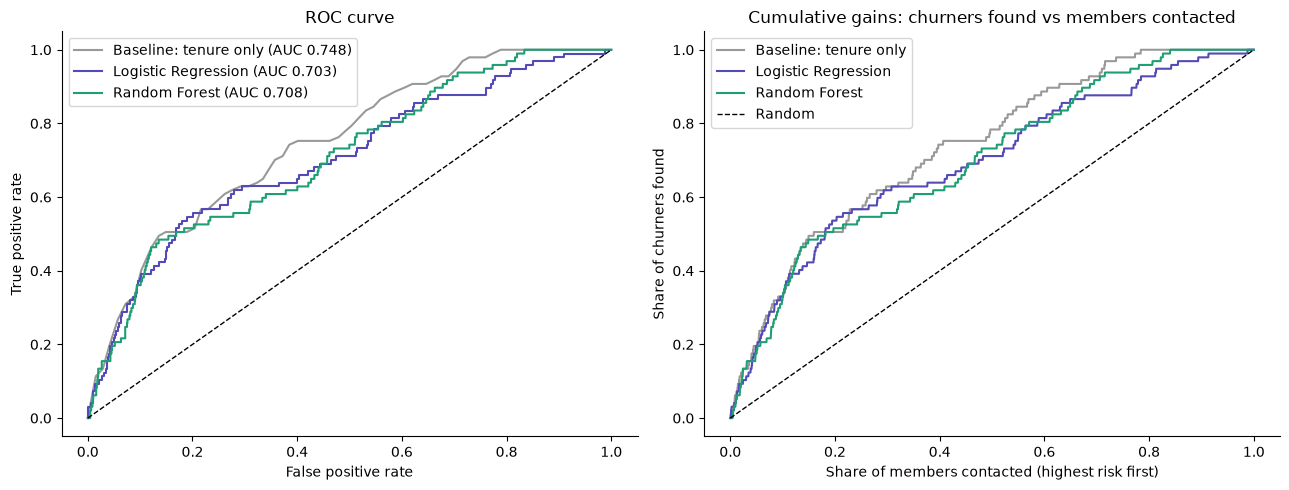

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colors = {"Baseline: tenure only": "#999999", "Logistic Regression": "#534AB7", "Random Forest": "#1D9E75"}

for name, p in test_scores.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=colors[name], label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
    order = np.argsort(-p)
    gain = np.cumsum(y_test.values[order]) / y_test.sum()
    axes[1].plot(np.arange(1, len(p) + 1) / len(p), gain, color=colors[name], label=name)

axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].set_title("ROC curve")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate"); axes[0].legend()
axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="Random")
axes[1].set_title("Cumulative gains: churners found vs members contacted")
axes[1].set_xlabel("Share of members contacted (highest risk first)"); axes[1].set_ylabel("Share of churners found")
axes[1].legend(); plt.tight_layout(); plt.show()

Selected model: Random Forest


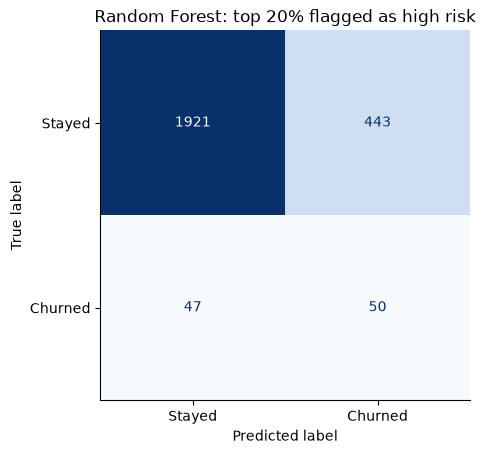

Members flagged        : 493 of 2,461
Precision (flagged who churned) : 10.1%  vs  3.9% base rate
Recall (churners caught)        : 51.5%


In [28]:
# Pick the better of the two full models using cross-validated AUC (on training data only)
best_name = max(["Logistic Regression", "Random Forest"],
                key=lambda n: cross_val_score(models[n][0], X_train[feature_cols], y_train, cv=cv, scoring="roc_auc").mean())
best_model = models[best_name][0]
print("Selected model:", best_name)

# Business rule: contact the 20% of members with the highest risk score
p = test_scores[best_name]
cutoff = np.quantile(p, 0.80)
flag = (p >= cutoff).astype(int)

ConfusionMatrixDisplay.from_predictions(y_test, flag, display_labels=["Stayed", "Churned"], cmap="Blues", colorbar=False)
plt.title(f"{best_name}: top 20% flagged as high risk"); plt.show()

print(f"Members flagged        : {flag.sum():,} of {len(flag):,}")
print(f"Precision (flagged who churned) : {precision_score(y_test, flag):.1%}  vs  {y_test.mean():.1%} base rate")
print(f"Recall (churners caught)        : {recall_score(y_test, flag):.1%}")

**What this means in practice:** flagging the top 20% (493 of 2,461 test members) gives a precision of about **10%**, about 2.6 times the 3.9% base rate. Roughly 1 in 10 retention offers reaches a member who really would have left, and about half of all churners are covered. Whether that is worth it depends on the cost of an offer versus the value of keeping a member.

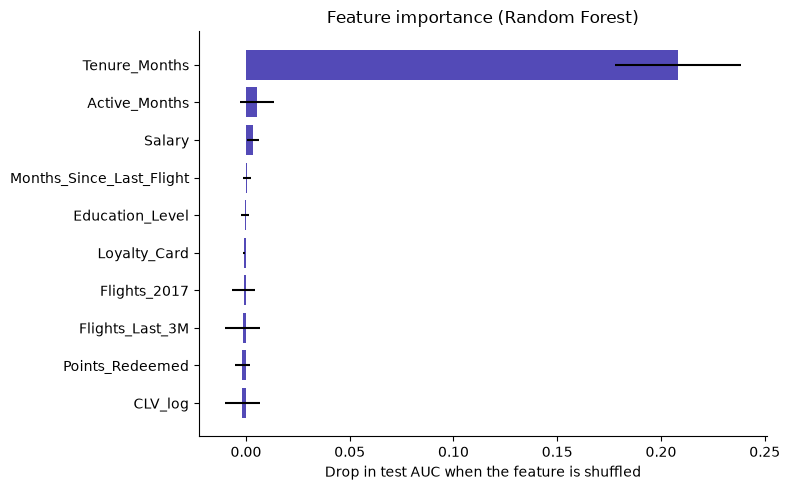

Tenure_Months               0.2082
Active_Months               0.0053
Salary                      0.0034
Months_Since_Last_Flight    0.0005
Education_Level            -0.0004
Loyalty_Card               -0.0010
Flights_2017               -0.0011
Flights_Last_3M            -0.0017
Points_Redeemed            -0.0017
CLV_log                    -0.0018


In [29]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(best_model, X_test, y_test, scoring="roc_auc", n_repeats=20, random_state=42)
imp_s = pd.Series(imp.importances_mean, index=feature_cols).sort_values()

plt.figure(figsize=(8, 5))
plt.barh(imp_s.index, imp_s.values, xerr=pd.Series(imp.importances_std, index=feature_cols)[imp_s.index], color="#534AB7")
plt.xlabel("Drop in test AUC when the feature is shuffled"); plt.title(f"Feature importance ({best_name})")
plt.tight_layout(); plt.show()
print(imp_s.sort_values(ascending=False).round(4).to_string())

**Permutation importance** shuffles one feature at a time and measures how much the test AUC drops.

- **`Tenure_Months` dominates** (shuffling it drops AUC by about 0.21).
- Every other feature is close to zero, meaning once the model knows tenure, the remaining features add almost nothing for this task.

This agrees with the exploration chart and with the baseline comparison above. (Permutation importance can understate features that overlap with each other, so treat the small values as "little unique information", not "useless".)

## 8. Risk tiers
A probability is more useful to marketing when it becomes an action list. Members are scored with **out-of-fold predictions**: each member is scored by a model that was trained without seeing that member, so the tier results below are not inflated by training data.

In [30]:
# Score EVERY member with a model that never saw that member (out-of-fold predictions)
data["risk_score"] = cross_val_predict(clone(best_model), X, y, cv=cv, method="predict_proba")[:, 1]

high_cut, med_cut = data["risk_score"].quantile(0.90), data["risk_score"].quantile(0.70)
data["risk_tier"] = np.where(data["risk_score"] >= high_cut, "High",
                     np.where(data["risk_score"] >= med_cut, "Medium", "Low"))

tiers = data.groupby("risk_tier").agg(members=("churned", "size"), churners=("churned", "sum"),
                                      churn_rate=("churned", "mean")).loc[["High", "Medium", "Low"]]
tiers["% of members"] = (tiers["members"] / len(data) * 100).round(1)
tiers["% of all churners"] = (tiers["churners"] / data["churned"].sum() * 100).round(1)
tiers["churn_rate"] = (tiers["churn_rate"] * 100).round(1)
display(tiers.rename(columns={"churn_rate": "2018 churn rate (%)"}))

,members,churners,2018 churn rate (%),% of members,% of all churners
risk_tier,,,,,
High,1231,173,14.1,10.0,35.6
Medium,2461,115,4.7,20.0,23.7
Low,8613,198,2.3,70.0,40.7


**Result:**

- The **High tier** is 10% of members but has a **14.1% churn rate (about 3.6x the average)** and holds 35.6% of all churners.
- The **Medium tier** churns at 4.7%.
- The **Low tier** churns at 2.3%, but because it is 70% of members it still contains 40.7% of all churners.

So the score is useful for **prioritising** retention effort, but it is not a crystal ball: many churners sit in the lower tiers.

## 9. Customer segmentation (K-Means)

Segmentation answers a different question from prediction: **what types of members do we have?** K-Means groups members with similar behaviour and value.

- Features: tenure, 2017 flights, active months, months since last flight, and log CLV. **Churn is not used**, so the groups reflect behaviour and value only.
- Features are **standardised** first, because K-Means uses distance and would otherwise be dominated by large-number features.
- Churn is checked afterwards as an independent test: if the segments are meaningful, their churn rates should differ.

k=2 | inertia 42,207 | silhouette 0.386
k=3 | inertia 32,030 | silhouette 0.293
k=4 | inertia 26,166 | silhouette 0.253
k=5 | inertia 22,526 | silhouette 0.251
k=6 | inertia 19,725 | silhouette 0.251


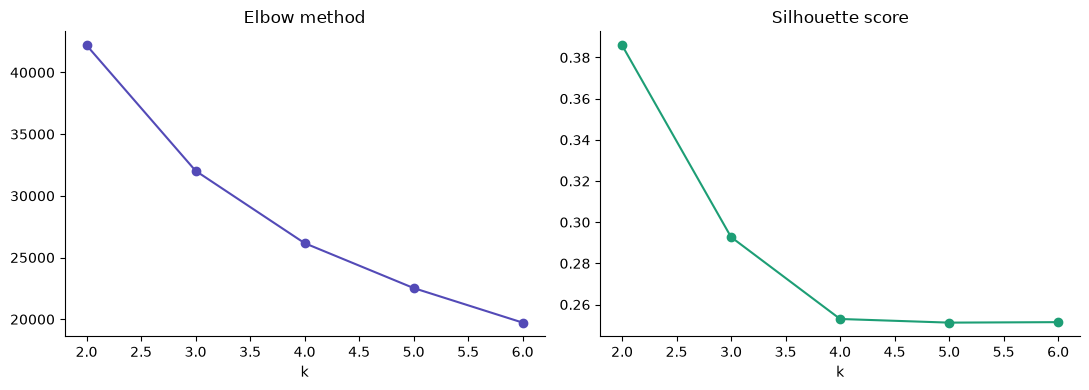

In [31]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Clustering uses 2017 behaviour and value only - NOT the churn label
cluster_cols = ["Tenure_Months", "Flights_2017", "Active_Months", "Months_Since_Last_Flight", "CLV_log"]
Z = StandardScaler().fit_transform(data[cluster_cols])

ks, inertia, sil = range(2, 7), [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Z)
    inertia.append(km.inertia_); sil.append(silhouette_score(Z, km.labels_))
    print(f"k={k} | inertia {km.inertia_:,.0f} | silhouette {sil[-1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(list(ks), inertia, "o-", color="#534AB7"); axes[0].set_title("Elbow method"); axes[0].set_xlabel("k")
axes[1].plot(list(ks), sil, "o-", color="#1D9E75"); axes[1].set_title("Silhouette score"); axes[1].set_xlabel("k")
plt.tight_layout(); plt.show()

**Choosing k:** the elbow curve bends gradually without a sharp corner. Silhouette (how well separated the groups are) is highest for k = 2 at 0.386, then drops to about 0.25 for k = 4-6. The clusters are therefore not sharply separated, which is normal for customer data where behaviour is a continuum.

**k = 4 is chosen for business reasons.** k = 2 would only split "active" from "inactive". k = 4 costs little extra silhouette compared with k = 5 or 6 and splits established members by customer value, which is something marketing can act on.

,members,tenure,flights_2017,active_months,months_since_last,avg_clv,2018 churn rate (%),% of members,% of all churners
cluster,,,,,,,,,
Established high-value,3958,39.3,20.7,7.5,0.6,13399.1,2.3,32.2,18.7
Established standard,4960,40.7,21.0,7.6,0.6,4152.5,2.6,40.3,26.1
New & light flyers,2774,13.7,9.8,3.8,0.9,6870.7,7.7,22.5,44.0
Dormant,613,26.6,0.2,0.1,11.9,8380.4,8.8,5.0,11.1


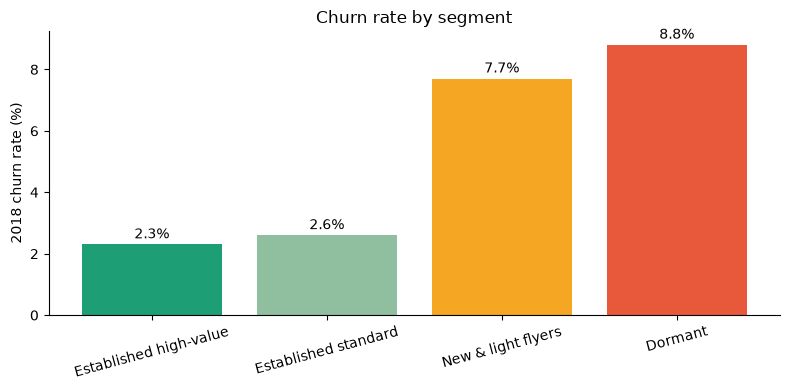

In [32]:
km = KMeans(n_clusters=4, random_state=42, n_init=10).fit(Z)
data["cluster"] = km.labels_

prof = data.groupby("cluster").agg(
    members=("churned", "size"), tenure=("Tenure_Months", "mean"), flights_2017=("Flights_2017", "mean"),
    active_months=("Active_Months", "mean"), months_since_last=("Months_Since_Last_Flight", "mean"),
    avg_clv=("CLV", "mean"), churn_rate=("churned", "mean"), churners=("churned", "sum"))

# Name clusters with simple rules (so names stay correct even if cluster numbers change)
names = {}
dormant = prof["flights_2017"].idxmin()
names[dormant] = "Dormant"
rest = prof.drop(index=dormant)
newbie = rest["tenure"].idxmin()
names[newbie] = "New & light flyers"
rest = rest.drop(index=newbie)
names[rest["avg_clv"].idxmax()] = "Established high-value"
names[rest["avg_clv"].idxmin()] = "Established standard"

data["segment"] = data["cluster"].map(names)
prof.index = prof.index.map(names)
prof["% of members"] = (prof["members"] / len(data) * 100).round(1)
prof["% of all churners"] = (prof["churners"] / prof["churners"].sum() * 100).round(1)
prof["churn_rate"] = (prof["churn_rate"] * 100).round(1)
order = ["Established high-value", "Established standard", "New & light flyers", "Dormant"]
display(prof.loc[order].drop(columns="churners").round(1).rename(columns={"churn_rate": "2018 churn rate (%)"}))

# Churn was NOT used to build the clusters, so these churn rates are an independent check
fig, ax = plt.subplots(figsize=(8, 4))
vals = prof.loc[order, "churn_rate"]
ax.bar(order, vals, color=["#1D9E75", "#8FBF9F", "#F5A623", "#E8593C"])
for i, v in enumerate(vals):
    ax.text(i, v + 0.2, f"{v:.1f}%", ha="center")
ax.set_ylabel("2018 churn rate (%)"); ax.set_title("Churn rate by segment"); plt.xticks(rotation=15)
plt.tight_layout(); plt.show()

**The four segments**

| Segment | Share of members | Profile | 2018 churn |
|---|---|---|---|
| Established high-value | 32% | Long tenure (about 39 months), regular flyers, **highest CLV (about 13,400)** | 2.3% |
| Established standard | 40% | Long tenure, regular flyers, lower CLV (about 4,200) | 2.6% |
| New & light flyers | 22% | **About 14 months tenure**, about 10 flights/year, active only about 4 months | **7.7%** |
| Dormant | 5% | Almost no flights in 2017 (0.2), about 12 months since last flight | **8.8%** |

**Key insights**

- Churn rates differ clearly across segments, so the segments capture real differences.
- **New & light flyers are 22% of members but 44% of all churners**, making them the biggest opportunity by volume.
- **Dormant members** have the highest rate but are small (5% of members, 11% of churners).
- **Value does not predict churn:** high-value and standard established members churn at nearly the same low rate (2.3% vs 2.6%). High CLV does not mean a member is safe or at risk.

In [33]:
ct = pd.crosstab(data["segment"], data["risk_tier"]).loc[order, ["High", "Medium", "Low"]]
display(ct)
print("\nRow percentages (share of each segment in each risk tier):")
display((ct.div(ct.sum(axis=1), axis=0) * 100).round(1))

risk_tier,High,Medium,Low
segment,,,
Established high-value,2,315,3641
Established standard,0,987,3973
New & light flyers,896,1151,727
Dormant,333,8,272



Row percentages (share of each segment in each risk tier):


risk_tier,High,Medium,Low
segment,,,
Established high-value,0.1,8.0,92.0
Established standard,0.0,19.9,80.1
New & light flyers,32.3,41.5,26.2
Dormant,54.3,1.3,44.4


**Segments and risk tiers agree:** 54% of Dormant and 32% of New & light members sit in the High risk tier, versus almost none of the Established members (2 of 3,958 high-value members). In other words, the risk model largely rediscovers the segments. That is a good consistency check, and it is also why the action list below can focus on specific groups. For example, the **896 High-risk New & light flyers** are the most urgent group.

## 10. Retention recommendations

| Segment | Members | What to do | How to measure |
|---|---|---|---|
| **New & light flyers** (highest priority) | 2,774 | Run an **onboarding journey for the first 12 months**: a bonus on the 2nd or 3rd flight, a nudge towards a first points redemption, check-ins around months 3 and 6. Start with the 896 who are High risk. | 12-month retention of new cohorts |
| **Dormant** | 613 | A low-cost **win-back offer** (for example bonus points on the next flight) by email. Keep spend small, since reactivation is uncertain. | Reactivation rate within 90 days |
| **Established high-value** | 3,958 | **Protect, do not discount.** Their churn is already low, so recognition and service perks (status benefits, early access) fit better than offers. Monitor for a sudden drop in activity. | Churn rate stays near 2%; spend per member |
| **Established standard** | 4,960 | Low-cost automated nurture, such as offers that encourage more flights or redemptions to grow their value. | Increase in flights per member |

**How to prove it works:** test every action as an **A/B test** with a holdout group that gets nothing. Without a holdout, any drop in churn cannot be credited to the campaign. These are recommendations from observed patterns, not proven effects.

In [34]:
out_cols = ["Loyalty Number", "segment", "risk_tier", "risk_score", "churned"] + feature_cols
data[out_cols].sort_values("risk_score", ascending=False).to_csv("airline_customer_risk_and_segments.csv", index=False)
print("Saved: airline_customer_risk_and_segments.csv", data[out_cols].shape)

Saved: airline_customer_risk_and_segments.csv (12305, 15)


## 11. Summary

- **Setup:** features from 2017, churn defined as cancelling in 2018, so predictions are genuine. 12,305 active members, 486 churners (3.95%).
- **Churn model:** ROC-AUC about 0.71; contacting the top 20% by risk reaches about half of churners (2.5-2.7x better than random). The top 10% risk tier churns at 14.1% versus 3.95% overall.
- **Main finding:** churn is mainly a **new-member problem**. Members in their first 6 months churn at 14.0% versus 1.3% for those with 49+ months. A tenure-only baseline matches the full models.
- **Segments:** four groups with different churn rates (2.3% to 8.8%). New & light flyers hold 44% of churners while being 22% of members.
- **Loyalty tier is not a useful risk signal**, and neither is customer value.
- **Output file:** `airline_customer_risk_and_segments.csv` (risk score, tier and segment per member).

## 12. Limitations

- **One year of outcomes:** only 486 churners in 2018, and 97 in the test set, so test metrics are noisy. The model has not been tested on a later year.
- **Only formal cancellations count as churn.** Members who quietly stop flying without cancelling are not labelled.
- **Limited history:** flight data covers only 2017-2018, so older behaviour is invisible.
- **Possible data issues:** some flights are dated before enrolment (left unchanged), and profile fields such as card tier, salary and CLV are snapshots whose date is unknown.
- **Associations, not causes:** the patterns show who churns, not why.
- **Segments are moderately separated** (silhouette about 0.25), so borders between them are blurry.

## 13. Interview cheat sheet

**30-second summary:** "I built a churn model for an airline loyalty programme. I used 2017 behaviour to predict who would cancel in 2018, so the prediction is genuinely forward-looking. The model reaches about half of churners by contacting the top 20% by risk. The main finding was that churn is mostly a new-member problem, so I segmented members with K-Means and recommended an onboarding programme for new members, win-back for dormant ones, and protection for high-value ones."

**Why predict 2018 from 2017?** Using the same months for features and label lets the model see the outcome through its inputs (a cancelled member has no later flights). Splitting by time makes it a real prediction.

**AUC is only about 0.71. Is that bad?** It is realistic. People cancel for reasons not in flight data. It is also honest: scores above 0.95 on churn problems usually point to leakage. The model is still about 2.6x better than random at finding churners.

**Why didn't the full models beat the tenure-only baseline?** Because tenure carries most of the signal. The differences are within cross-validation noise. It shows the baseline check was worth doing: extra features and complex models did not add value.

**Why not use accuracy?** Only about 4% churn, so predicting "nobody churns" is 96% accurate and useless. I used ROC-AUC, PR-AUC and the share of churners caught in the top 20%.

**Why k = 4?** k = 2 scores best statistically but only separates active from inactive. k = 4 splits established members by value, which marketing can act on. I stated that silhouette is only about 0.25.

**How were risk tiers validated?** Each member was scored by a model that never saw them (out-of-fold predictions), and I compared the tiers with the actual 2018 churn.

**What next?** Validate on a later year, try survival analysis (time-to-cancel), add a cost-benefit view for choosing the contact threshold, and run an A/B test of the retention actions.